# ПР-10 · Уровень C
**Задача:** сравнить K-Means, DBSCAN и иерархическую кластеризацию на данных сложной формы и выбрать подходящий метод.

**Идея.** Специально делаю данные, на которых K-Means должен работать плохо:
- два «полумесяца» — невыпуклые кластеры;
- маленький плотный кластер — другая плотность и другой размер;
- немного случайного шума — выбросы.

Настоящие метки сохраняю отдельно в `y_true`. В кластеризации они не участвуют, только в проверке в конце (через ARI).

In [1]:
import sys, sklearn, numpy as np, pandas as pd, matplotlib, scipy
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram
print("Python", sys.version.split()[0], "| sklearn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__, "| scipy", scipy.__version__)

Python 3.14.0 | sklearn 1.9.1 | numpy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2 | scipy 1.18.1


In [2]:
# Оформление графиков
plt.rcParams.update({"font.family": "sans-serif", "font.size": 12,
                     "font.sans-serif": ["IBM Plex Sans", "DejaVu Sans", "Arial"],
                     "figure.facecolor": "#F5F4EF", "axes.facecolor": "#F5F4EF",
                     "savefig.facecolor": "#F5F4EF", "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = np.array(["#A84C14", "#2A5DB0", "#3F8F6B", "#7A5BA6", "#C9A227", "#5C6B7A"])
NOISE = "#B8BCC2"
import os; os.makedirs("figs", exist_ok=True)

## Шаг 1. Подготовка данных

In [3]:
rng = np.random.RandomState(42)
X_moons, y_moons = make_moons(n_samples=400, noise=0.06, random_state=42)          # 2 полумесяца по 200 точек
X_blob, _ = make_blobs(n_samples=80, centers=[[2.6, 1.6]], cluster_std=0.12,
                       random_state=42)                                            # маленький плотный кластер
X_noise = rng.uniform([-1.5, -1.0], [3.2, 2.2], size=(20, 2))                      # 20 случайных точек-выбросов

X_raw = np.vstack([X_moons, X_blob, X_noise])
y_true = np.r_[y_moons, np.full(80, 2), np.full(20, -1)]   # -1 = шум (только для проверки!)

X = StandardScaler().fit_transform(X_raw)
print("Размер:", X.shape)
vals, cnts = np.unique(y_true, return_counts=True)
print("Настоящие группы (метка: точек):", {int(v): int(c) for v, c in zip(vals, cnts)})

Размер: (500, 2)
Настоящие группы (метка: точек): {-1: 20, 0: 200, 1: 200, 2: 80}


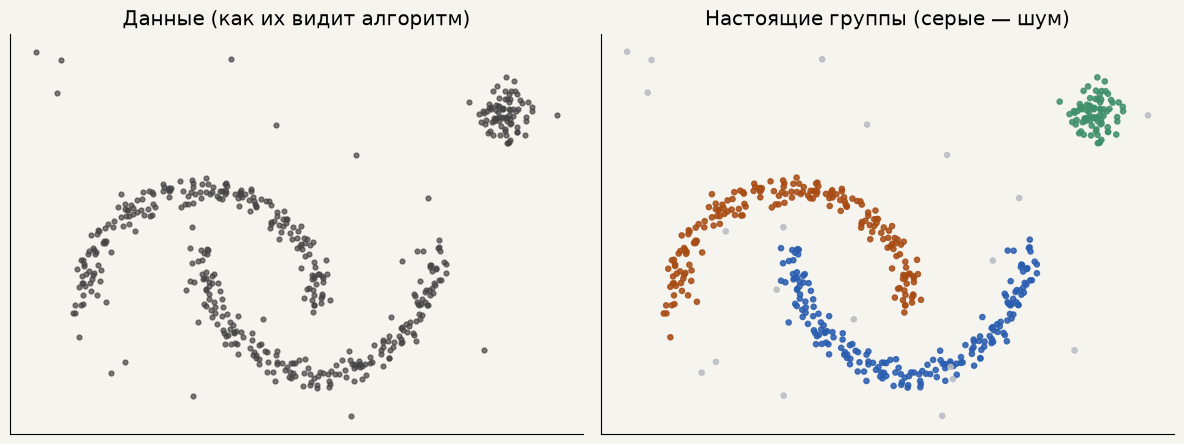

In [4]:
def draw(ax, labels, title):
    labels = np.asarray(labels)
    col = np.where(labels == -1, NOISE, COLORS[labels % len(COLORS)])
    ax.scatter(X[:, 0], X[:, 1], c=col, s=14, alpha=0.85)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(X[:, 0], X[:, 1], c="#444", s=12, alpha=0.7); axes[0].set_title("Данные (как их видит алгоритм)")
axes[0].set_xticks([]); axes[0].set_yticks([])
draw(axes[1], y_true, "Настоящие группы (серые — шум)")
fig.tight_layout(); fig.savefig("figs/pr10_C_data.png", dpi=160)
plt.show()

## Шаг 2. K-Means
Настоящих групп 3, поэтому беру k = 3. Это даже подсказка в пользу K-Means: на реальных данных k ещё пришлось бы угадывать.

Размеры кластеров: [212  83 205]


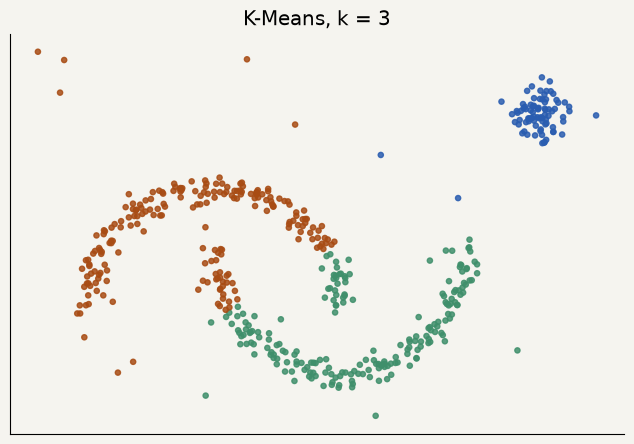

In [5]:
km_labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
print("Размеры кластеров:", np.bincount(km_labels))
fig, ax = plt.subplots(figsize=(6.5, 4.6))
draw(ax, km_labels, "K-Means, k = 3")
fig.tight_layout(); fig.savefig("figs/pr10_C_kmeans.png", dpi=160)
plt.show()

K-Means разрезал полумесяцы поперёк. Он всегда строит выпуклые кластеры вокруг центров, а граница между кластерами — прямая линия. Изогнутую форму он не может описать. Выбросы тоже распределились по кластерам: «шума» у K-Means не бывает.

## Шаг 3. DBSCAN
### 3.1. Сначала — с параметрами по умолчанию (как делать не надо)

In [6]:
db_default = DBSCAN().fit_predict(X)   # eps=0.5, min_samples=5
print("Кластеров:", len(set(db_default)) - (-1 in db_default), "| шум:", (db_default == -1).sum())
print("Размеры:", np.bincount(db_default[db_default >= 0]))

Кластеров: 2 | шум: 8
Размеры: [411  81]


С `eps = 0.5` радиус соседства слишком большой для этих (отмасштабированных) данных. Оба полумесяца сливаются в один кластер. Это не значит, что метод не работает. Просто параметры нужно подбирать.

### 3.2. Подбор параметров по графику k-расстояний
- `min_samples`: обычное правило — примерно 2 × число признаков. Признаков 2, поэтому беру `min_samples = 4`.
- `eps`: для каждой точки считаю расстояние до её 4-го ближайшего соседа (сама точка считается первой) и сортирую. Точки внутри кластеров дают маленькие расстояния, выбросы — большие. Там, где график резко идёт вверх («колено»), находится граница между «плотными» точками и шумом. Это значение и берём как `eps`.

Процентили k-расстояния: {50: 0.064, 90: 0.109, 95: 0.147, 97: 0.223, 99: 0.777}


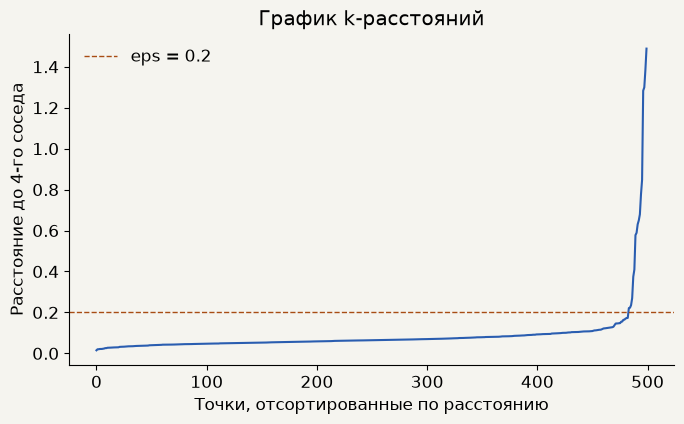

In [7]:
min_samples = 4
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
k_dist = np.sort(dist[:, -1])
print("Процентили k-расстояния:",
      {p: round(float(np.percentile(k_dist, p)), 3) for p in (50, 90, 95, 97, 99)})

eps = 0.2
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(k_dist, color=COLORS[1])
ax.axhline(eps, color=COLORS[0], ls="--", lw=1, label=f"eps = {eps}")
ax.set_xlabel("Точки, отсортированные по расстоянию")
ax.set_ylabel(f"Расстояние до {min_samples}-го соседа")
ax.set_title("График k-расстояний")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figs/pr10_C_kdist.png", dpi=160)
plt.show()

~95% точек имеют k-расстояние меньше 0.15, и только последние несколько процентов (выбросы) резко уходят вверх. Колено находится примерно на 0.15–0.25, поэтому беру **eps = 0.2**. Ниже проверяю, насколько результат чувствителен к выбору параметров.

In [8]:
rows = []
for e in [0.1, 0.15, 0.2, 0.25, 0.3, 0.5]:
    for ms in [4, 8]:
        lab = DBSCAN(eps=e, min_samples=ms).fit_predict(X)
        rows.append({"eps": e, "min_samples": ms,
                     "кластеров": len(set(lab)) - (-1 in lab), "шум": int((lab == -1).sum())})
print(pd.DataFrame(rows).to_string(index=False))

 eps  min_samples  кластеров  шум
0.10            4          9   36
0.10            8         20  107
0.15            4          3   18
0.15            8          3   26
0.20            4          3   14
0.20            8          3   14
0.25            4          3   13
0.25            8          3   13
0.30            4          2   12
0.30            8          2   12
0.50            4          2    8
0.50            8          2    8


Кластеров: 3 | шум: 14
Размеры: [205 200  81]


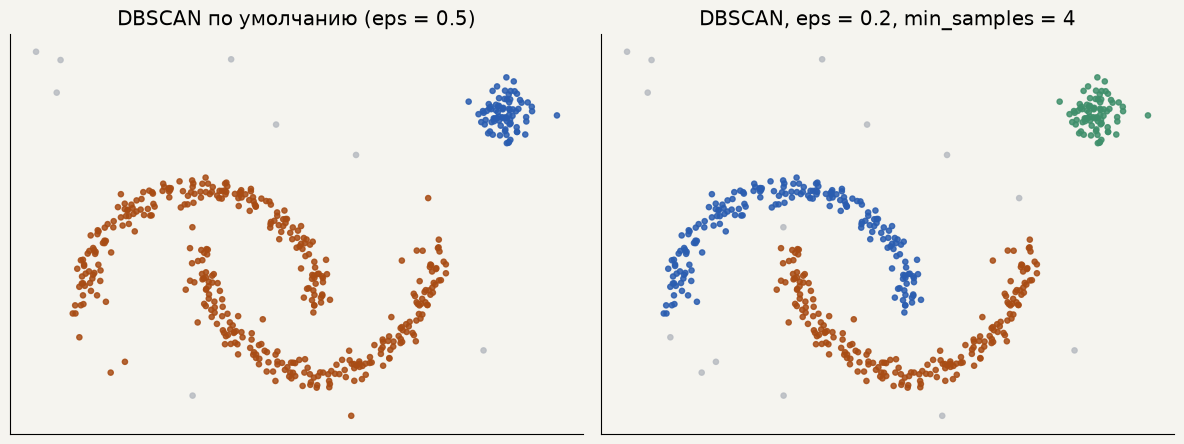

In [9]:
db_labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
print("Кластеров:", len(set(db_labels)) - (-1 in db_labels), "| шум:", (db_labels == -1).sum())
print("Размеры:", np.bincount(db_labels[db_labels >= 0]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
draw(axes[0], db_default, "DBSCAN по умолчанию (eps = 0.5)")
draw(axes[1], db_labels, f"DBSCAN, eps = {eps}, min_samples = {min_samples}")
fig.tight_layout(); fig.savefig("figs/pr10_C_dbscan.png", dpi=160)
plt.show()

С подобранными параметрами DBSCAN нашёл ровно 3 кластера правильной формы, а выбросы отметил как шум (серые). В диапазоне eps от 0.15 до 0.25 результат почти не меняется, то есть выбор не «подогнан» под одно число. При eps ≥ 0.3 полумесяцы снова сливаются.

## Шаг 4. Иерархическая кластеризация и дендрограмма
Пробую два способа объединения кластеров (linkage):
- **ward** — объединяет так, чтобы меньше всего росла дисперсия. По смыслу похож на K-Means;
- **single** — расстояние между кластерами = расстояние между двумя *ближайшими* точками. Умеет следовать за изогнутой «цепочкой» точек.

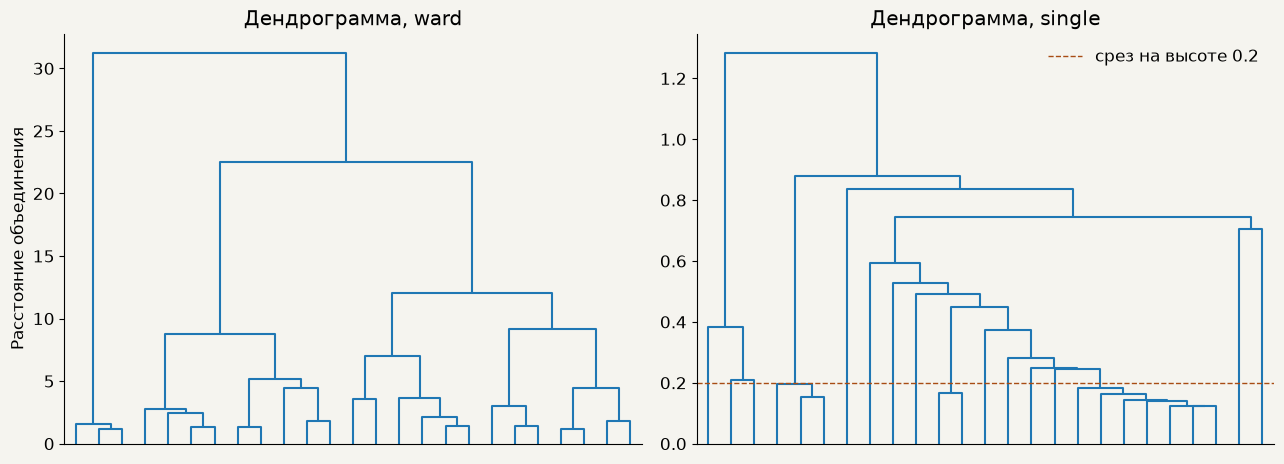

Последние 6 объединений single (высота, размер нового кластера):
[[  0.593 413.   ]
 [  0.705   2.   ]
 [  0.746 415.   ]
 [  0.836 416.   ]
 [  0.878 497.   ]
 [  1.283 500.   ]]


In [10]:
Z_ward = linkage(X, method="ward")
Z_single = linkage(X, method="single")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
dendrogram(Z_ward, ax=axes[0], truncate_mode="lastp", p=25, no_labels=True, color_threshold=0)
axes[0].set_title("Дендрограмма, ward"); axes[0].set_ylabel("Расстояние объединения")
dendrogram(Z_single, ax=axes[1], truncate_mode="lastp", p=25, no_labels=True, color_threshold=0)
axes[1].axhline(0.2, color=COLORS[0], ls="--", lw=1, label="срез на высоте 0.2")
axes[1].set_title("Дендрограмма, single"); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig("figs/pr10_C_dendrograms.png", dpi=160)
plt.show()

print("Последние 6 объединений single (высота, размер нового кластера):")
print(np.round(Z_single[-6:, 2:], 3))

In [11]:
ward_labels = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)
single3 = AgglomerativeClustering(n_clusters=3, linkage="single").fit_predict(X)
print("ward, 3 кластера:   ", np.bincount(ward_labels))
print("single, 3 кластера: ", np.bincount(single3))

# Режу дерево single по высоте 0.2 (по дендрограмме) вместо фиксированного числа кластеров
raw = AgglomerativeClustering(n_clusters=None, distance_threshold=0.2, linkage="single").fit_predict(X)
sizes = np.bincount(raw)
print("single, срез 0.2:    всего групп", len(sizes), "| размеры по убыванию:", sorted(sizes.tolist(), reverse=True))

# Группы меньше 5 точек считаю выбросами
big = np.where(sizes >= 5)[0]
hier_labels = np.full(len(raw), -1)
for new, old in enumerate(big):
    hier_labels[raw == old] = new
print("После отсечения мелких групп: кластеров", len(big), "| выбросов", (hier_labels == -1).sum())

ward, 3 кластера:    [272  81 147]
single, 3 кластера:  [416   3  81]
single, срез 0.2:    всего групп 16 | размеры по убыванию: [205, 200, 81, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
После отсечения мелких групп: кластеров 3 | выбросов 14


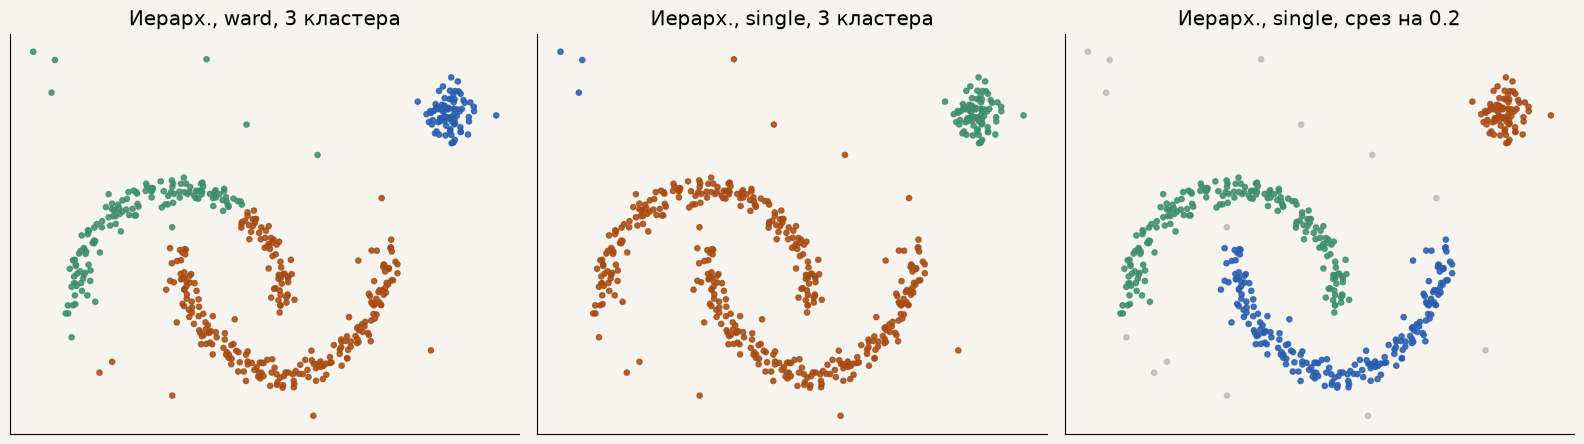

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
draw(axes[0], ward_labels, "Иерарх., ward, 3 кластера")
draw(axes[1], single3, "Иерарх., single, 3 кластера")
draw(axes[2], hier_labels, "Иерарх., single, срез на 0.2")
fig.tight_layout(); fig.savefig("figs/pr10_C_hierarchical.png", dpi=160)
plt.show()

**Что даёт дендрограмма сверх обычного разбиения:**
- показывает **всю историю объединений**, а не одно разбиение. По ней видно, на какой высоте какие группы сливаются, и можно выбрать число кластеров уже после обучения;
- **длинные вертикальные отрезки** означают, что группа долго остаётся отдельной. Это признак настоящего кластера. На дендрограмме single внутри трёх настоящих групп точки соединяются на маленькой высоте (до ~0.2), а сами группы сливаются гораздо позже: два полумесяца — только на высоте ≈ 0.59, плотный кластер присоединяется на ≈ 0.88. Поэтому срез на 0.2 разделяет их правильно;
- **выбросы** видны как одиночные точки, которые присоединяются в самом конце. Из-за этого single с `n_clusters=3` выдал 1 большой кластер и 2 крошечных: три последних объединения — это выбросы, а не настоящие кластеры. Поэтому дерево правильнее резать по высоте, а не по числу кластеров;
- по дендрограмме ward видно, что ward «уверенно» делит данные на 3 группы, но это неправильные группы (как у K-Means). Дендрограмма показывает структуру, которую нашёл метод, а не обязательно правильную.

## Шаг 5. Сравнение методов по метрикам
- **Силуэт** и **Davies–Bouldin** — внутренние метрики: используют только сами данные (силуэт — чем больше, тем лучше; DB — чем меньше, тем лучше). Шумовые точки при расчёте не учитываю.
- **ARI** — сравнение с настоящими метками `y_true` (они были скрыты от алгоритмов). Считаю по точкам, которые на самом деле не шум.

In [13]:
results = {"K-Means (k=3)": km_labels,
           "DBSCAN по умолчанию": db_default,
           f"DBSCAN (eps={eps}, ms={min_samples})": db_labels,
           "Иерарх. ward (3)": ward_labels,
           "Иерарх. single (3)": single3,
           "Иерарх. single (срез 0.2)": hier_labels}

real = y_true != -1
rows = []
for name, lab in results.items():
    m = lab != -1
    rows.append({"метод": name,
                 "кластеров": len(set(lab[m])),
                 "шум": int((~m).sum()),
                 "силуэт": round(silhouette_score(X[m], lab[m]), 3),
                 "Davies-Bouldin": round(davies_bouldin_score(X[m], lab[m]), 3),
                 "ARI с истиной": round(adjusted_rand_score(y_true[real], lab[real]), 3)})
table = pd.DataFrame(rows).set_index("метод")
print(table.to_string())

                           кластеров  шум  силуэт  Davies-Bouldin  ARI с истиной
метод                                                                           
K-Means (k=3)                      3    0   0.546           0.657          0.600
DBSCAN по умолчанию                2    8   0.576           0.438          0.374
DBSCAN (eps=0.2, ms=4)             3   14   0.463           0.816          0.996
Иерарх. ward (3)                   3    0   0.505           0.684          0.622
Иерарх. single (3)                 3    0   0.504           0.435          0.374
Иерарх. single (срез 0.2)          3   14   0.463           0.816          0.996


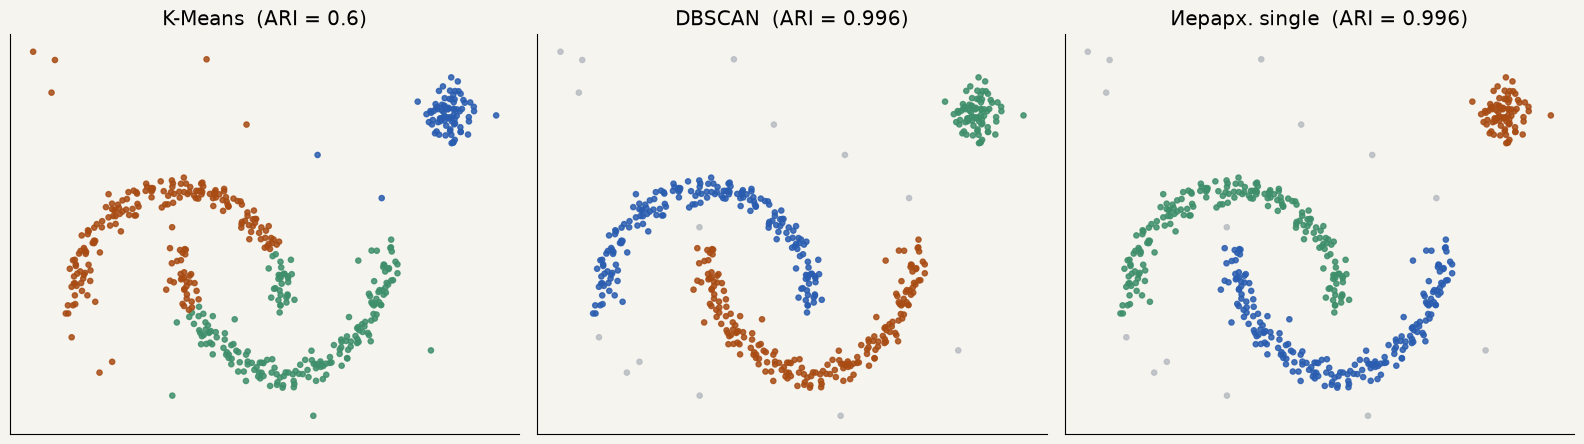

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
draw(axes[0], km_labels, f"K-Means  (ARI = {table.iloc[0, -1]})")
draw(axes[1], db_labels, f"DBSCAN  (ARI = {table.iloc[2, -1]})")
draw(axes[2], hier_labels, f"Иерарх. single  (ARI = {table.iloc[5, -1]})")
fig.tight_layout(); fig.savefig("figs/pr10_C_compare.png", dpi=160)
plt.show()

**Важное наблюдение про метрики.** По силуэту K-Means выглядит *лучше* DBSCAN, хотя на картинке видно, что он ошибся. Силуэт и Davies–Bouldin сами предполагают, что хорошие кластеры — компактные «шары». Для изогнутых полумесяцев это не так, и метрики «наказывают» правильное разбиение. Самый высокий силуэт (0.576) вообще у DBSCAN по умолчанию, который слил два полумесяца в один кластер. ARI с настоящими метками показывает реальную картину: DBSCAN и иерархическая single почти идеальны (≈ 1.0), K-Means и ward — около 0.6.

Вывод: на данных сложной формы нельзя выбирать метод только по силуэту. Нужно смотреть на график и, если есть, на скрытую разметку.

## Шаг 6. Вывод: какой метод выбрать и ограничения каждого

**Для этих данных лучше всего подходит DBSCAN.** Он нашёл правильные кластеры любой формы, сам определил их количество и отдельно отметил выбросы. Параметры подбираются осознанно по графику k-расстояний, и результат устойчив в диапазоне eps 0.15–0.25.

Иерархическая кластеризация с **single linkage** дала такой же хороший результат. Но для этого пришлось смотреть на дендрограмму, резать её по высоте и вручную отсекать мелкие группы-выбросы.

| Метод | Плюсы | Ограничения |
|---|---|---|
| **K-Means** | Быстрый, простой, хорошо работает на компактных «шарах» одного размера (как в уровнях A и B) | Нужно заранее задать k; находит только выпуклые кластеры; чувствителен к выбросам и масштабу; плохо работает при разной плотности и размере кластеров |
| **DBSCAN** | Кластеры любой формы; сам находит число кластеров; выделяет шум | Чувствителен к `eps` и `min_samples` (по умолчанию не работает); один `eps` на все данные, поэтому при сильно разной плотности не найдёт сразу и плотные, и разреженные кластеры; плохо работает при большом числе признаков |
| **Иерархическая** | Дендрограмма показывает всю структуру; число кластеров можно выбрать после обучения; single linkage находит цепочки сложной формы | Результат сильно зависит от linkage (ward ≈ K-Means, single чувствителен к выбросам и «мостикам» между кластерами); нужна память O(n²), поэтому для больших данных медленно |

**Итого:** если кластеры компактные и примерно одного размера, достаточно K-Means. Если форма сложная и есть шум, лучше DBSCAN, а дендрограмма полезна, чтобы понять структуру данных и выбрать число кластеров.